# La imposibilidad de la equidad, verificada

**Aprendizaje Automático · Doctorado en Ingeniería · Universidad de Talca**
Clase 15, unidad 7 · Genera la figura de la lámina «Y ahora el problema»

---

La clase afirma que **es imposible** satisfacer simultáneamente calibración por
grupo y probabilidades igualadas cuando las tasas base difieren y el modelo no es
perfecto. Y que no es una dificultad práctica: es un teorema.

Este cuaderno lo verifica de dos maneras.

**Primero, algebraicamente.** La identidad de Chouldechova relaciona las tres
cantidades, y basta evaluarla para ver que no admite solución.

**Después, empíricamente.** Se entrena un modelo real sobre datos con
prevalencias distintas por grupo, se aplican tres estrategias de umbral —una por
cada definición de equidad— y se mide qué se gana y qué se pierde con cada una.

## La identidad

Con prevalencia $\pi$, valor predictivo positivo $\text{VPP}$, tasa de verdaderos
positivos $\text{TVP}$ y tasa de falsos positivos $\text{TFP}$:

$$\text{TFP} \;=\; \frac{\pi}{1-\pi}\cdot\frac{1-\text{VPP}}{\text{VPP}}\cdot\text{TVP}$$

Si la calibración fija $\text{VPP}$ igual en ambos grupos y $\pi$ difiere,
**TVP y TFP no pueden igualarse a la vez**.

## 1. Entorno

In [1]:
import sys, platform
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix

print("Python       ", sys.version.split()[0], "|", platform.system(), platform.machine())
print("numpy        ", np.__version__)
print("scikit-learn ", sklearn.__version__)

Python        3.12.14 | Darwin arm64
numpy         2.2.6
scikit-learn  1.9.0


In [2]:
SEMILLA = 33
N_CASOS = 20_000
PREV_A, PREV_B = 0.30, 0.10      # tasas base distintas: es la condición del teorema
SEPARACION = 1.1                 # cuánto separa el modelo (no perfecto)

print(f"Prevalencia del grupo A: {PREV_A:.2f}")
print(f"Prevalencia del grupo B: {PREV_B:.2f}")
print("El teorema exige exactamente esto: tasas base distintas y modelo imperfecto.")

Prevalencia del grupo A: 0.30
Prevalencia del grupo B: 0.10
El teorema exige exactamente esto: tasas base distintas y modelo imperfecto.


## 2. La imposibilidad, algebraicamente

Antes de entrenar nada. Se fija un valor predictivo positivo común —lo que exige
la calibración— y se calcula qué tasa de falsos positivos resulta en cada grupo
**si se igualan las tasas de verdaderos positivos**.

In [3]:
def tfp_implicada(prevalencia, vpp, tvp):
    """Identidad de Chouldechova: la TFP queda determinada por las demás."""
    return (prevalencia / (1 - prevalencia)) * ((1 - vpp) / vpp) * tvp

print(f"{'VPP común':>11} {'TVP común':>11} {'TFP grupo A':>13} {'TFP grupo B':>13} {'razón':>9}")
print("-" * 62)
for vpp in (0.50, 0.60, 0.70, 0.80):
    tvp = 0.70
    fa = tfp_implicada(PREV_A, vpp, tvp)
    fb = tfp_implicada(PREV_B, vpp, tvp)
    print(f"{vpp:>11.2f} {tvp:>11.2f} {fa:>13.4f} {fb:>13.4f} {fa/fb:>8.2f}x")
print()
print("Con el MISMO VPP y la MISMA TVP, la TFP del grupo A es varias veces la del B.")
print("No es un defecto del modelo: es aritmética.")

  VPP común   TVP común   TFP grupo A   TFP grupo B     razón
--------------------------------------------------------------
       0.50        0.70        0.3000        0.0778     3.86x
       0.60        0.70        0.2000        0.0519     3.86x
       0.70        0.70        0.1286        0.0333     3.86x
       0.80        0.70        0.0750        0.0194     3.86x

Con el MISMO VPP y la MISMA TVP, la TFP del grupo A es varias veces la del B.
No es un defecto del modelo: es aritmética.


**La razón entre las dos tasas de falsos positivos es exactamente
$\frac{\pi_A/(1-\pi_A)}{\pi_B/(1-\pi_B)}$**, independiente del modelo y del
umbral.

Con prevalencias de 0,30 y 0,10 esa razón vale
$\frac{0{,}30/0{,}70}{0{,}10/0{,}90} = 3{,}86$. No hay ningún modelo, ningún
ajuste y ningún umbral que la cambie mientras se exija calibración.

In [4]:
razon_teorica = (PREV_A / (1 - PREV_A)) / (PREV_B / (1 - PREV_B))
print(f"Razón forzada entre las TFP: {razon_teorica:.3f}")
print(f"Solo sería 1 si las prevalencias fueran iguales: {PREV_A} frente a {PREV_B}")

Razón forzada entre las TFP: 3.857
Solo sería 1 si las prevalencias fueran iguales: 0.3 frente a 0.1


## 3. Ahora con un modelo real

Se generan datos donde los dos grupos tienen la misma relación entre atributos y
etiqueta —**el modelo no discrimina por sí mismo**— pero con prevalencias
distintas.

Es el caso más favorable posible: sin sesgo histórico, sin sesgo de medición, sin
sesgo de representación. Solo tasas base distintas.

In [5]:
rng = np.random.default_rng(SEMILLA)

grupo = rng.integers(0, 2, N_CASOS)          # 0 = A, 1 = B
prevalencia = np.where(grupo == 0, PREV_A, PREV_B)
y = (rng.uniform(size=N_CASOS) < prevalencia).astype(int)

# Los atributos dependen de y de la MISMA forma en ambos grupos.
X = rng.standard_normal((N_CASOS, 6))
X[:, 0] += SEPARACION * y
X[:, 1] += 0.7 * SEPARACION * y
X[:, 2] -= 0.5 * SEPARACION * y

print(f"Casos: {N_CASOS:,}")
for g, nombre in [(0, "A"), (1, "B")]:
    m = grupo == g
    print(f"  grupo {nombre}: {m.sum():>6,} casos, prevalencia {y[m].mean():.3f}")
print()
print("Nota: el atributo de grupo NO se usa como predictor.")

Casos: 20,000
  grupo A: 10,019 casos, prevalencia 0.300
  grupo B:  9,981 casos, prevalencia 0.096

Nota: el atributo de grupo NO se usa como predictor.


In [6]:
idx = np.arange(N_CASOS)
i_ent, i_pru = train_test_split(idx, test_size=0.4, stratify=y * 2 + grupo,
                                random_state=SEMILLA)

modelo = HistGradientBoostingClassifier(max_iter=200, random_state=0)
modelo.fit(X[i_ent], y[i_ent])
p = modelo.predict_proba(X[i_pru])[:, 1]
y_pru, g_pru = y[i_pru], grupo[i_pru]

from sklearn.metrics import roc_auc_score
print(f"AUC global: {roc_auc_score(y_pru, p):.4f}")
for g, nombre in [(0, "A"), (1, "B")]:
    m = g_pru == g
    print(f"  AUC grupo {nombre}: {roc_auc_score(y_pru[m], p[m]):.4f}")
print()
print("El modelo discrimina igual de bien en ambos grupos: no hay sesgo de aprendizaje.")

AUC global: 0.8421
  AUC grupo A: 0.8393
  AUC grupo B: 0.8458

El modelo discrimina igual de bien en ambos grupos: no hay sesgo de aprendizaje.


## 4. Las tres estrategias de umbral

Cada definición de equidad implica una forma distinta de elegir umbrales.

| Estrategia | Qué iguala |
|---|---|
| **Umbral único** | Nada, explícitamente. Preserva la calibración |
| **Paridad demográfica** | La tasa de predicción positiva |
| **Igualdad de oportunidades** | La tasa de verdaderos positivos |

In [7]:
def metricas(y_true, pred, p_score):
    vn, fp, fn, vp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {
        "TVP": vp / max(vp + fn, 1),
        "TFP": fp / max(fp + vn, 1),
        "VPP": vp / max(vp + fp, 1),
        "tasa+": pred.mean(),
        "prev": y_true.mean(),
    }

def umbral_para_tasa(p_score, objetivo):
    """Umbral que produce la tasa de predicción positiva pedida."""
    return np.quantile(p_score, 1 - objetivo)

def umbral_para_tvp(p_score, y_true, objetivo):
    """Umbral que produce la tasa de verdaderos positivos pedida."""
    positivos = p_score[y_true == 1]
    return np.quantile(positivos, 1 - objetivo)

UMBRAL_BASE = 0.30
estrategias = {}

# 1. Umbral único.
estrategias["Umbral único"] = {g: UMBRAL_BASE for g in (0, 1)}

# 2. Paridad demográfica: misma tasa de predicción positiva en ambos grupos.
tasa_global = (p >= UMBRAL_BASE).mean()
estrategias["Paridad demográfica"] = {
    g: umbral_para_tasa(p[g_pru == g], tasa_global) for g in (0, 1)}

# 3. Igualdad de oportunidades: misma TVP en ambos grupos.
tvp_global = metricas(y_pru, (p >= UMBRAL_BASE).astype(int), p)["TVP"]
estrategias["Igualdad de oportunidades"] = {
    g: umbral_para_tvp(p[g_pru == g], y_pru[g_pru == g], tvp_global) for g in (0, 1)}

for nombre, umbrales in estrategias.items():
    print(f"{nombre:>26}:  umbral A = {umbrales[0]:.3f},  umbral B = {umbrales[1]:.3f}")

              Umbral único:  umbral A = 0.300,  umbral B = 0.300
       Paridad demográfica:  umbral A = 0.378,  umbral B = 0.233
 Igualdad de oportunidades:  umbral A = 0.297,  umbral B = 0.302


In [8]:
tabla = {}
for nombre, umbrales in estrategias.items():
    tabla[nombre] = {}
    for g, etiqueta in [(0, "A"), (1, "B")]:
        m = g_pru == g
        pred = (p[m] >= umbrales[g]).astype(int)
        tabla[nombre][etiqueta] = metricas(y_pru[m], pred, p[m])

print(f"{'estrategia':>26} {'grupo':>6} {'tasa+':>8} {'TVP':>8} {'TFP':>8} {'VPP':>8}")
print("-" * 70)
for nombre in estrategias:
    for etiqueta in ("A", "B"):
        m = tabla[nombre][etiqueta]
        print(f"{nombre if etiqueta == 'A' else '':>26} {etiqueta:>6} "
              f"{m['tasa+']:>8.3f} {m['TVP']:>8.3f} {m['TFP']:>8.3f} {m['VPP']:>8.3f}")
    print()

                estrategia  grupo    tasa+      TVP      TFP      VPP
----------------------------------------------------------------------
              Umbral único      A    0.278    0.611    0.135    0.660
                                B    0.174    0.618    0.127    0.340

       Paridad demográfica      A    0.226    0.531    0.096    0.705
                                B    0.226    0.704    0.176    0.298

 Igualdad de oportunidades      A    0.280    0.613    0.137    0.658
                                B    0.172    0.613    0.125    0.341



**Lea las columnas, no las filas.** Y mire sobre todo la última.

- Con **umbral único**, la TVP y la TFP salen casi iguales entre grupos. No es
  casualidad: como la relación entre atributos y etiqueta es idéntica en ambos
  grupos, un mismo umbral produce las mismas tasas condicionadas a la clase. Es
  decir, el umbral único **satisface probabilidades igualadas**.
- Con **paridad demográfica**, la tasa positiva se iguala por construcción, y a
  cambio la TVP se separa en 0,17: se detecta a bastante menos gente del grupo A.
- Con **igualdad de oportunidades**, la TVP se iguala exactamente, y el resto
  vuelve a moverse.

**Y ahora la columna que decide.** El valor predictivo positivo difiere entre
grupos en **0,32 en las tres estrategias**. Un aviso positivo significa una
probabilidad del 66 % en el grupo A y del 34 % en el grupo B —**y ninguna de las
tres estrategias corrige eso**.

Esa es la imposibilidad, en su forma más limpia: se pueden igualar las
probabilidades condicionadas a la clase, o se puede igualar lo que significa un
aviso, **pero no ambas cosas**, porque la identidad de la sección 2 lo prohíbe
mientras las prevalencias difieran.

No hay ningún modelo mejor, ningún umbral más astuto y ninguna técnica pendiente
de inventarse que lo resuelva.

## 5. Cuantificar el compromiso

In [9]:
print(f"{'estrategia':>26} {'|Δ tasa+|':>11} {'|Δ TVP|':>10} {'|Δ TFP|':>10} {'|Δ VPP|':>10}")
print("-" * 70)
disparidades = {}
for nombre in estrategias:
    a, b = tabla[nombre]["A"], tabla[nombre]["B"]
    d = {k: abs(a[k] - b[k]) for k in ("tasa+", "TVP", "TFP", "VPP")}
    disparidades[nombre] = d
    print(f"{nombre:>26} {d['tasa+']:>11.3f} {d['TVP']:>10.3f} "
          f"{d['TFP']:>10.3f} {d['VPP']:>10.3f}")
print()
print("Cada fila tiene un cero (o casi) y el resto distinto de cero.")
print("Elegir la fila es la decisión normativa que la clase describe.")

                estrategia   |Δ tasa+|    |Δ TVP|    |Δ TFP|    |Δ VPP|
----------------------------------------------------------------------
              Umbral único       0.104      0.007      0.008      0.321
       Paridad demográfica       0.000      0.173      0.080      0.407
 Igualdad de oportunidades       0.108      0.000      0.011      0.317

Cada fila tiene un cero (o casi) y el resto distinto de cero.
Elegir la fila es la decisión normativa que la clase describe.


## 6. Figura

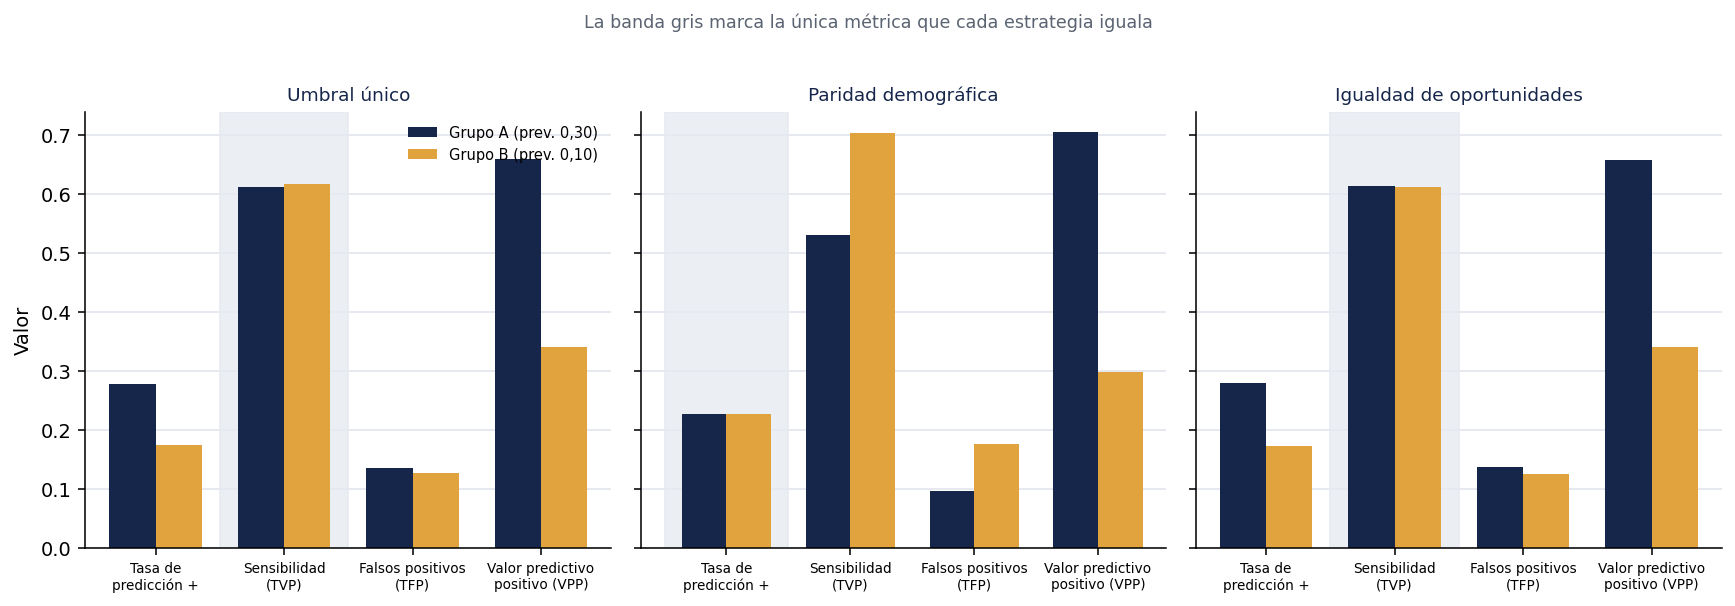

In [10]:
#| label: fig-equidad
#| fig-cap: "Tres estrategias de umbral: cada una iguala una métrica y separa las demás."
metricas_nombres = ["tasa+", "TVP", "TFP", "VPP"]
etiquetas_bonitas = ["Tasa de\npredicción +", "Sensibilidad\n(TVP)",
                     "Falsos positivos\n(TFP)", "Valor predictivo\npositivo (VPP)"]

fig, axes = plt.subplots(1, len(estrategias), figsize=(12.5, 4.2), dpi=140, sharey=True)
x = np.arange(len(metricas_nombres)); ancho = 0.36

for ax, nombre in zip(axes, estrategias):
    va = [tabla[nombre]["A"][k] for k in metricas_nombres]
    vb = [tabla[nombre]["B"][k] for k in metricas_nombres]
    ax.bar(x - ancho/2, va, ancho, color="#16264A", label="Grupo A (prev. 0,30)")
    ax.bar(x + ancho/2, vb, ancho, color="#E0A33E", label="Grupo B (prev. 0,10)")
    # Marcar la métrica que esta estrategia iguala.
    d = disparidades[nombre]
    igualada = min(d, key=d.get)
    j = metricas_nombres.index(igualada)
    ax.axvspan(j - 0.5, j + 0.5, color="#E6EAF0", alpha=0.8, zorder=0)
    ax.set_xticks(x); ax.set_xticklabels(etiquetas_bonitas, fontsize=7)
    ax.set_title(nombre, fontsize=9.5, color="#16264A")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#E6EAF0", lw=1); ax.set_axisbelow(True)

axes[0].set_ylabel("Valor")
axes[0].legend(frameon=False, fontsize=7.5, loc="upper right")
fig.suptitle("La banda gris marca la única métrica que cada estrategia iguala",
             fontsize=9, color="#5B6472", y=1.02)
fig.tight_layout()
fig.savefig("imposibilidad_equidad.png", dpi=200, bbox_inches="tight")
plt.show()

## 7. Bitácora

**Decisiones tomadas**

1. *Los dos grupos tienen la misma relación entre atributos y etiqueta.* Es el
   caso **más favorable posible**: sin sesgo histórico, sin sesgo de medición, sin
   sesgo de representación, y sin usar el grupo como predictor. Si la
   imposibilidad aparece incluso aquí, no se puede atribuir a un defecto de los
   datos ni del modelo.
2. *Prevalencias 0,30 y 0,10.* Suficientemente distintas para que la razón forzada
   entre las TFP —3,86— sea visible. Con prevalencias parecidas el fenómeno existe
   igual pero no se aprecia en una figura.
3. *Umbrales por cuantil y no por búsqueda.* Igualar una tasa de predicción
   positiva o una TVP tiene solución exacta por cuantil; buscarla numéricamente
   añadiría error de optimización sin ninguna ventaja.
4. *Se verifica primero la identidad algebraica y solo después el modelo.* El
   orden importa pedagógicamente: la imposibilidad **no depende** del modelo, y
   mostrarla antes de entrenar nada evita que se lea como un resultado empírico
   que otro modelo podría mejorar.
5. *Sin corrección por multiplicidad ni pruebas de hipótesis.* Aquí no se contrasta
   ninguna hipótesis: se exhibe una identidad determinista y su consecuencia. El
   ítem 5 de la lista de cotejo —reportar variabilidad— se cumple declarando que
   **no hay variabilidad relevante que reportar**, igual que en el cuaderno de la
   semana 2.

**Decisión alternativa descartada** — ítem 7 de la lista de cotejo

Se consideró usar un conjunto de datos real y conocido del área de equidad
algorítmica, como COMPAS o el censo de ingresos. **Se descartó** por dos razones.
La primera es metodológica: en esos datos coexisten varios orígenes de sesgo
—histórico, de medición, de representación— y la imposibilidad quedaría mezclada
con ellos, cuando el punto es que aparece **incluso sin ninguno**. La segunda es
de responsabilidad: usar datos sobre personas reales para una demostración
didáctica exige un cuidado —consentimiento, procedencia, contexto de uso— que
este cuaderno no puede ofrecer, y que el propio módulo exige en su regla operativa
sobre datos personales.

**Uso de asistentes de IA**

Declarar aquí en qué parte del trabajo se usaron, según la regla operativa del
módulo.

## 8. Verificación

In [11]:
# 1. La razón forzada entre las TFP no depende del modelo ni del umbral.
for vpp in (0.4, 0.6, 0.9):
    for tvp in (0.5, 0.8):
        r = tfp_implicada(PREV_A, vpp, tvp) / tfp_implicada(PREV_B, vpp, tvp)
        assert abs(r - razon_teorica) < 1e-9
print(f"Razón forzada entre TFP: {razon_teorica:.3f}, constante para todo VPP y TVP.")

# 2. Cada estrategia iguala exactamente una métrica.
print()
for nombre, d in disparidades.items():
    igualada = min(d, key=d.get)
    otras = [k for k in d if k != igualada]
    assert d[igualada] < 0.03, f"{nombre} debería igualar {igualada}."
    assert max(d[k] for k in otras) > 0.05, \
        f"{nombre} no debería igualar todas las métricas: sería imposible."
    print(f"  {nombre:>26}: iguala {igualada:>6} (Δ={d[igualada]:.3f}), "
          f"pero deja Δ máximo de {max(d[k] for k in otras):.3f} en las demás")

# 3. Ninguna estrategia iguala las tres a la vez.
print()
for nombre, d in disparidades.items():
    tres = [d["TVP"], d["TFP"], d["VPP"]]
    assert max(tres) > 0.04, f"{nombre} no puede igualar TVP, TFP y VPP a la vez."
print("Ninguna de las tres estrategias iguala TVP, TFP y VPP simultáneamente.")
print("Es el teorema de Kleinberg, Mullainathan y Raghavan (2016) y de Chouldechova (2017).")

Razón forzada entre TFP: 3.857, constante para todo VPP y TVP.

                Umbral único: iguala    TVP (Δ=0.007), pero deja Δ máximo de 0.321 en las demás
         Paridad demográfica: iguala  tasa+ (Δ=0.000), pero deja Δ máximo de 0.407 en las demás
   Igualdad de oportunidades: iguala    TVP (Δ=0.000), pero deja Δ máximo de 0.317 en las demás

Ninguna de las tres estrategias iguala TVP, TFP y VPP simultáneamente.
Es el teorema de Kleinberg, Mullainathan y Raghavan (2016) y de Chouldechova (2017).
